# From a weakness to a weight repair
## A controlled walkthrough of the repair workflow

The goal is to propose a small weight edit that improves the model's ability to perform its intended XNOR task. This notebook demonstrates the entire **calibration workflow** using an intentionally weakened checkpoint and a known reversal of that change.

**This is a scripted synthetic example, not an LLM response or a blinded discovery.** It uses temporary sessions and the development validation split; no real reviewer session is created and the private final evaluation set is not used.

In [1]:
from pathlib import Path
import hashlib, json, sys, tempfile
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

ROOT = Path.cwd().resolve()
if not (ROOT / 'experiment.json').exists():
    ROOT = ROOT.parent
if not (ROOT / 'experiment.json').exists():
    raise FileNotFoundError('Open this notebook from the project root or notebooks/ directory.')
sys.path.insert(0, str(ROOT / 'src'))
from weight_reader.evidence import export_review
from weight_reader.probe import probe_round
from weight_reader.repair import import_repair, validate_repair
from weight_reader.model import WeightReaderMLP

config = json.loads((ROOT / 'experiment.json').read_text())
checkpoint = ROOT / 'checkpoints' / 'editing_start_seed_11.pt'
template = ROOT / 'prompts' / 'REPAIR_PROMPT.md'
if not checkpoint.is_file():
    raise FileNotFoundError('The weakened checkpoint is missing. See README for how to recreate it.')
OUT = ROOT / 'results' / 'figures'
OUT.mkdir(parents=True, exist_ok=True)
torch.set_num_threads(1)
plt.rcParams.update({'figure.dpi':110, 'savefig.dpi':300, 'font.size':11,
                     'axes.spines.top':False, 'axes.spines.right':False,
                     'axes.titleweight':'bold', 'figure.facecolor':'white'})
def export_figure(fig,name):
    fig.savefig(OUT / f'{name}.png',bbox_inches='tight',facecolor='white')
    fig.savefig(OUT / f'{name}.svg',bbox_inches='tight',facecolor='white')
def sha(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

temporary = tempfile.TemporaryDirectory(prefix='weight-reader-repair-demo-')
demo_root = Path(temporary.name)
session_id = 'synthetic-repair-demo'
original_hash = sha(checkpoint)
packet_path, prompt_path = export_review(demo_root, session_id, checkpoint,
    'adaptive_probes', 'synthetic-example', 'calibration', config, template, task='repair')
packet = json.loads(packet_path.read_text())
print('Temporary calibration session created; no LLM was called.')

Temporary calibration session created; no LLM was called.


## 1. What is the repair task?

The reviewer receives the network weights and is told the intended rule: the logit should be positive when x₀ and x₁ have the same nonzero sign, and nonpositive otherwise. Unlike the separate ablation-prediction task, the repair task **does disclose the XNOR target**.

The reviewer can propose **one multiplicative change** to a scalar, a matrix row, or a matrix column. The multiplier must be finite and between 0 and 2, inclusive. The reviewer should describe the expected benefit and possible regression. In a blinded study, the reference checkpoint and how the defect was introduced remain private.

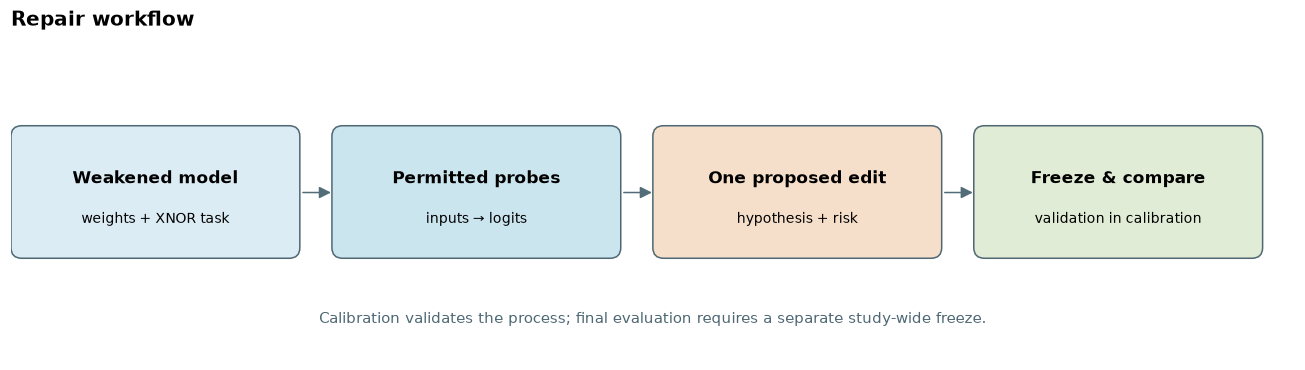

In [2]:
fig, ax = plt.subplots(figsize=(12,3.5))
ax.set(xlim=(0,12),ylim=(0,3)); ax.axis('off')
items=[(.1,'Weakened model','weights + XNOR task','#dcecf4'),
       (3.1,'Permitted probes','inputs → logits','#cbe5ef'),
       (6.1,'One proposed edit','hypothesis + risk','#f6dfca'),
       (9.1,'Freeze & compare','validation in calibration','#e0ecd5')]
for x,title,sub,color in items:
    ax.add_patch(FancyBboxPatch((x,1.05),2.5,1.05,boxstyle='round,pad=.1',facecolor=color,edgecolor='#4f6873'))
    ax.text(x+1.25,1.7,title,ha='center',va='center',weight='bold')
    ax.text(x+1.25,1.32,sub,ha='center',va='center',fontsize=9)
for x in (2.7,5.7,8.7):
    ax.add_patch(FancyArrowPatch((x,1.57),(x+.32,1.57),arrowstyle='-|>',mutation_scale=16,color='#536d78'))
ax.text(6,.34,'Calibration validates the process; final evaluation requires a separate study-wide freeze.',ha='center',fontsize=10,color='#4d6773')
ax.set_title('Repair workflow',loc='left',pad=10)
fig.tight_layout(); export_figure(fig,'12_repair_workflow'); plt.show()

## 2. Gather permitted evidence

This demonstration uses the **adaptive** condition: four rounds of eight inputs. The batches below are scripted by the notebook author to exercise the relay. An actual reviewer would choose later batches based on earlier logits.

We examine some inputs in Q++, where x₀ > 0 and x₁ > 0. The target is class 1 there, so a nonpositive logit indicates an error for that input. No labels or ablation results are returned by the relay.

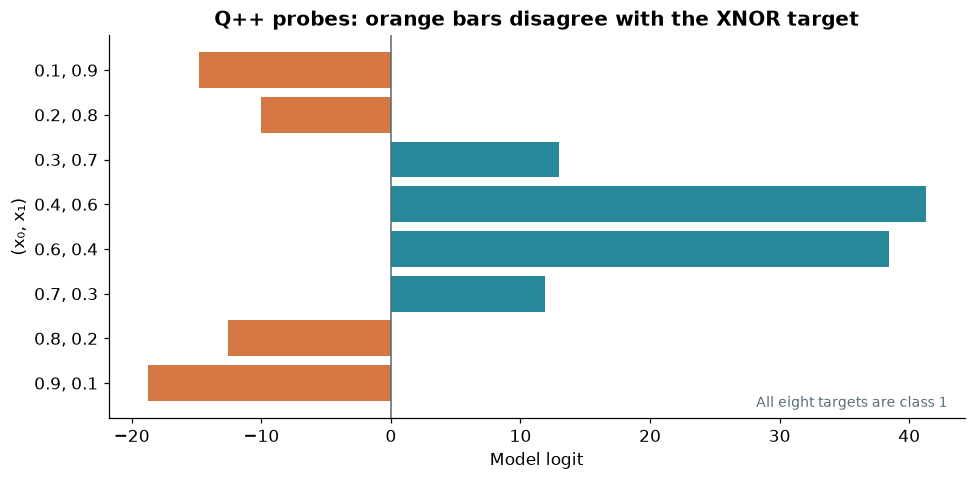

Completed scripted probe rounds: 4 ; total inputs: 32


In [3]:
batches = [
 [[.5,.5,0,0],[.8,.2,0,0],[.5,-.5,0,0],[-.5,.5,0,0],[-.5,-.5,0,0],[.2,.8,0,0],[.3,.7,0,0],[.7,.3,0,0]],
 [[.1,.9,0,0],[.2,.8,0,0],[.3,.7,0,0],[.4,.6,0,0],[.6,.4,0,0],[.7,.3,0,0],[.8,.2,0,0],[.9,.1,0,0]],
 [[.8,.2,a,b] for a,b in [(0,0),(.8,0),(-.8,0),(0,.8),(0,-.8),(.8,.8),(-.8,-.8),(.8,-.8)]],
 [[v,1-v,0,0] for v in [.05,.15,.25,.35,.65,.75,.85,.95]],
]
probe_results=[]
for i, inputs in enumerate(batches, 1):
    probe_results.append(probe_round(demo_root, session_id, i, {'inputs':inputs,'hypothesis':'Scripted demonstration.'}))
round2=probe_results[1]
xs=np.array(round2['inputs']); logits=np.array(round2['logits'])
fig,ax=plt.subplots(figsize=(9,4.5))
labels=[f'{x[0]:.1f}, {x[1]:.1f}' for x in xs]
ax.barh(np.arange(8),logits,color=np.where(logits>0,'#27889a','#d47743'))
ax.axvline(0,color='#536a74',lw=1); ax.invert_yaxis()
ax.set(yticks=np.arange(8),yticklabels=labels,xlabel='Model logit',ylabel='(x₀, x₁)',title='Q++ probes: orange bars disagree with the XNOR target')
ax.text(.98,.03,'All eight targets are class 1',ha='right',transform=ax.transAxes,color='#566c76',fontsize=9)
fig.tight_layout(); export_figure(fig,'13_repair_probe_evidence'); plt.show()
print('Completed scripted probe rounds:',len(probe_results),'; total inputs:',sum(len(x['inputs']) for x in probe_results))

## 3. Submit and freeze a specific edit

For this controlled demonstration, we know the weakness was introduced by multiplying **column 5 of the second layer's weight matrix by 0.5**. The example proposal multiplies that column by 2, reversing the known change. This is a sanity check of the workflow, not evidence that a reviewer found a repair.

In a real session, the response would contain the packet ID, hypothesis, edit, and expected effect. The importer archives the exact response, validates the allowed edit, applies it to a copied checkpoint, and freezes hashes. The original checkpoint remains untouched.

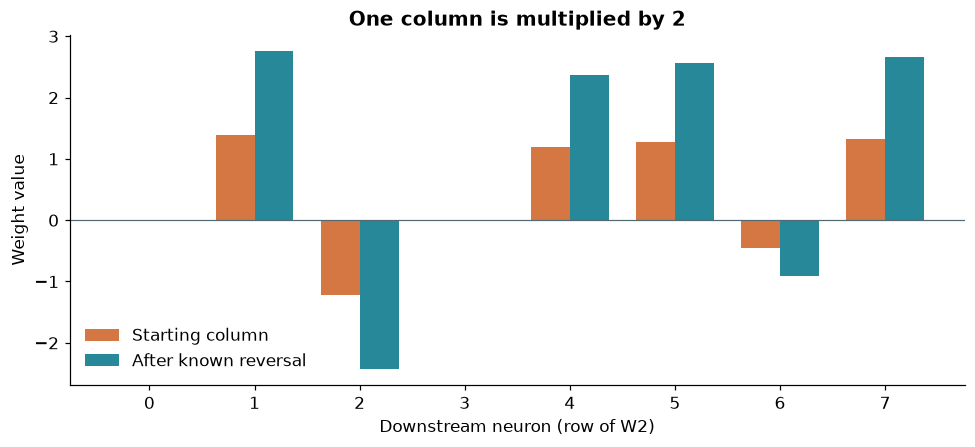

Frozen status: frozen_not_evaluated
Original checkpoint unchanged: True
Exact synthetic proposal archived: True


In [4]:
proposal = {
    'packet_id':packet['packet_id'],
    'hypothesis':'Synthetic demonstration: reverse the known column scaling.',
    'edit':{'parameter':'fc2.weight','index':[None,5],'scale':2.0},
    'expected_effect':'Restore the reference column; this is not an independent reviewer discovery.'
}
response_path = demo_root / 'synthetic_response.json'
response_path.write_text(json.dumps(proposal,indent=2)+'\n')
frozen_path = import_repair(demo_root,session_id,response_path)
frozen = json.loads(frozen_path.read_text())
before_state=torch.load(frozen_path.parent/'checkpoint.pt',map_location='cpu',weights_only=True)
after_state=torch.load(frozen_path.parent/'repair_checkpoint.pt',map_location='cpu',weights_only=True)
before=before_state['fc2.weight'][:,5].numpy()
after=after_state['fc2.weight'][:,5].numpy()
fig,ax=plt.subplots(figsize=(9,4.2))
idx=np.arange(len(before)); width=.37
ax.bar(idx-width/2,before,width,label='Starting column',color='#d47743')
ax.bar(idx+width/2,after,width,label='After known reversal',color='#27889a')
ax.axhline(0,color='#536a74',lw=.8)
ax.set(xticks=idx,xlabel='Downstream neuron (row of W2)',ylabel='Weight value',title='One column is multiplied by 2')
ax.legend(frameon=False); fig.tight_layout(); export_figure(fig,'14_repair_weight_edit'); plt.show()
print('Frozen status:',frozen['status'])
print('Original checkpoint unchanged:',sha(checkpoint)==original_hash)
print('Exact synthetic proposal archived:',(demo_root/'responses/raw'/session_id/'original.txt').read_bytes()==response_path.read_bytes())

## 4. Compare on development validation data

The calibration comparison scores the frozen starting and edited checkpoints on the **same** validation examples. It reports overall and quadrant accuracy so an apparent improvement does not hide regressions. These are development results: repeated tuning against this split can overfit it.

The main-study candidates and evaluation protocol must be frozen together before an untouched final evaluation. That study-wide freeze and held-out scoring are not yet implemented.

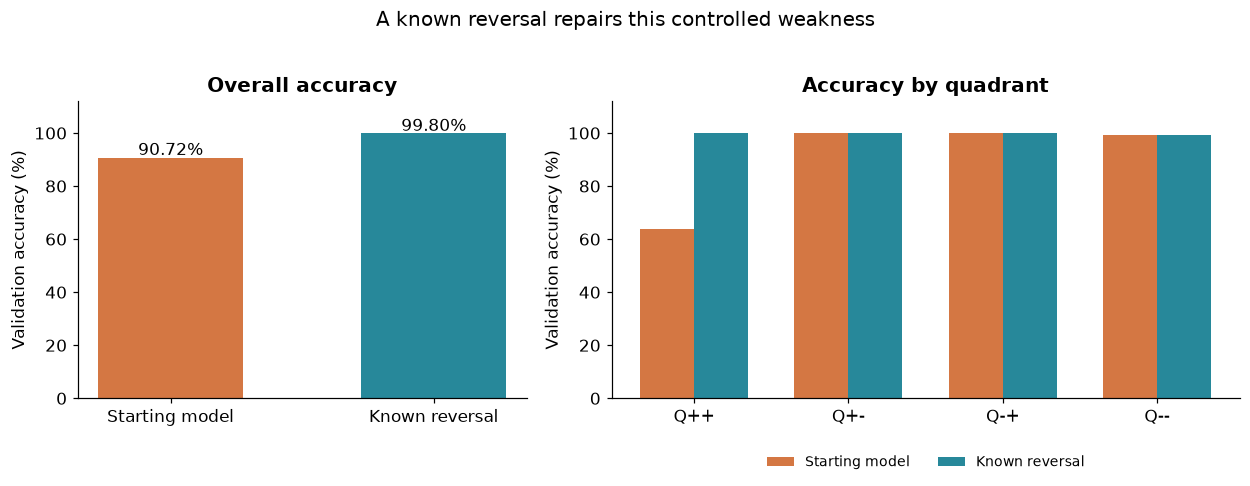

Accuracy change: +9.08 percentage points
Validation examples: 1024
No final evaluation data used.


In [5]:
comparison=validate_repair(demo_root,session_id,config)
qnames=['Q++','Q+-','Q-+','Q--']
fig,axes=plt.subplots(1,2,figsize=(11.5,4.4),gridspec_kw={'width_ratios':[1,1.4]})
values=[comparison['before']['accuracy']*100,comparison['after']['accuracy']*100]
bars=axes[0].bar(['Starting model','Known reversal'],values,color=['#d47743','#27889a'],width=.55)
for b in bars: axes[0].text(b.get_x()+b.get_width()/2,b.get_height()+1,f'{b.get_height():.2f}%',ha='center')
axes[0].set(ylim=(0,112),ylabel='Validation accuracy (%)',title='Overall accuracy')
idx=np.arange(4); width=.35
for pos,key,label,color in [(-width/2,'before','Starting model','#d47743'),(width/2,'after','Known reversal','#27889a')]:
    vals=[comparison[key]['quadrants'][q]['accuracy']*100 for q in qnames]
    axes[1].bar(idx+pos,vals,width,label=label,color=color)
axes[1].set(xticks=idx,xticklabels=qnames,ylim=(0,112),ylabel='Validation accuracy (%)',title='Accuracy by quadrant')
axes[1].legend(frameon=False,fontsize=9,loc='upper center',bbox_to_anchor=(.5,-.15),ncol=2)
fig.suptitle('A known reversal repairs this controlled weakness',y=1.02,fontsize=13)
fig.tight_layout(); export_figure(fig,'15_repair_validation'); plt.show()
print('Accuracy change:',f"{comparison['accuracy_change']*100:+.2f} percentage points")
print('Validation examples:',comparison['before']['count'])
print('No final evaluation data used.')

## What this demonstrates—and what it does not

- A controlled defect can be repaired by a specific, auditable weight edit; the tooling archives and freezes the proposal.
- The example uses prior knowledge of the defect. It is **not** evidence that an LLM inferred the correct edit from weights or probes.
- A real comparison needs separate reviewer sessions, preserved responses, fixed evidence budgets, and a predeclared evaluation. The held-out final set should be used only after the whole comparison is frozen.
- The ablation-prediction task asks what disabling a neuron will do; this repair task asks for an edit intended to improve performance. The two tasks answer different questions.